# Instrument Function

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/05-scattering/02-instrument_function.ipynb)

A measured reflectivity, transmissivity, or polarization change is typically an average over the angular and spectral distribution of the incident light and, in time-resolved experiments, over the temporal resolution, scaled by the footprint of the beam on the sample, and lifted by a background, which together form the instrument function of the experiment.
In this example, the instrument function of all scattering simulations is introduced, which is set by the {py:class}`InstrumentParameters <udkm1Dsim.simulations.parameter_groups.InstrumentParameters>` in `sim.instrument`.
It starts with the choice between the convolution and the quadrature of a resolution, followed by their applications.
See the [scattering overview](#example_scattering_overview) for the scattering formalisms and their methods.

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

from udkm1Dsim.simulations.scattering import instrument

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

try:
    plt.style.use(["mbistyles.base", "mbistyles.paper"])  # matplotlib styles of the MBI
except OSError:
    pass  # mbistyles is not installed, the default matplotlib style is used

## Instrument Parameters

The settings of the instrument fall into two groups.

**Experiment:** the properties of the instrument, which change the results and are typically known from the experiment or fitted:

| | profile | FWHM | further settings |
|---|---|---|---|
| angle | `theta_resolution` | `theta_width` (deg) | `theta_eta`, `theta_offset` (deg) |
| photon energy | `energy_resolution` | `energy_width` (eV) | `energy_eta`, `energy_offset` (eV), `spectrum` |
| delay | `delay_resolution` | `delay_width` (ps) | `delay_eta` |
| beam | `footprint` | `beam_width` (mm) | `sample_length` (mm) |
| intensity | | | `I0`, `background` |

- The profiles of the resolution are `none` (default), `box`, `gauss`, `lorentz`, or `pseudo_voigt`, the latter with the Lorentzian fraction `eta`.
  A resolution needs both, its profile and its width, otherwise a warning is given.
- The widths are scalars or arrays, i.e. the `theta_width` along the angles or of the shape (M, N) of the M photon energies and N angles of the experiment, and the `energy_width` along the photon energies.
  Varying widths describe e.g. a curvature of the sample of the radius $R$, whose footprint of a beam of the width $b$ spreads the angle by about $b / (R \sin\vartheta)$, or a spectral bandwidth of constant $\Delta E / E$.
- The `spectrum` of the source contains its components, e.g. the $K_{\alpha 1}$ and $K_{\alpha 2}$ lines of an X-ray tube, see the [dynamical X-ray example](#example_dynamical_xray), or higher harmonics of a monochromator.
- The temporal resolution, e.g. the cross-correlation of the pump and probe pulses, applies to the inhomogeneous results only.
- The `footprint` of a `box` or `gauss` beam on the sample scales the reflected intensities only.
- The `I0` and `background` scale the intensities to $I_0 I + I_\mathrm{bkg}$, e.g. for fits, see the [data fitting example](#example_data_fitting).

**Calculation:** the numerical evaluation of the resolution, which should not change the results, once it is converged, see the next section:

| | mode | nodes | number of nodes | truncation (FWHM) |
|---|---|---|---|---|
| angle | `theta_mode` | `theta_nodes` | `theta_points` | `theta_range` |
| photon energy | `energy_mode` | `energy_nodes` | `energy_points` | `energy_range` |
| delay | always convolved | | | `delay_range` |

- `theta_mode` and `energy_mode`:
  - `quadrature` (default): the simulation is calculated at shifted nodes around every point of the experiment and summed with their weights, which works for any grid, but costs one calculation per node,
  - `convolution`: the result of a single calculation is convolved on the grid of the experiment, which is fast, but needs a grid that is dense compared to the FWHM,
  - `qz` (energy only): the spectral spread is approximated by a spread of the angle at the same scattering vector $q_z$, which avoids calculations at shifted photon energies, but is valid away from absorption edges only.
- `theta_nodes` and `energy_nodes` of the quadrature:
  - `uniform` (default): equidistant nodes weighted by the profile, which are robust for narrow features, e.g. Bragg peaks or resonances,
  - `gaussian_quadrature`: Gauss-Hermite nodes of a `gauss` or Gauss-Legendre nodes of a `box` profile, which integrate smooth curves with few nodes, but are not available for the other profiles.
- `theta_points` and `energy_points`: the number of nodes of the quadrature (default 7), where an odd number contains the unshifted node, which should be increased until the result does not change anymore.
- `theta_range`, `energy_range`, and `delay_range`: the truncation of the profile at $\pm$ `range` times the FWHM (default 2) for the uniform nodes and the convolution, which needs to be larger for the long tails of a `lorentz` or `pseudo_voigt` profile, but is not used by the `gaussian_quadrature` and a `box` profile.

Bare numbers of the angles are degrees, of the photon energies eV, of the delay widths ps, and of the lengths mm.
The instrument applies to the reflectivity and transmissivity and to the rotation and ellipticity, but not to the Jones matrices, the fields, and the absorption.
Its printed tables list the numbers as parameters with their symbols and units and the texts as options.
An instrument with all its defaults is not active, so that the results and their hashes are the ones without an instrument:

In [2]:
ud.InstrumentParameters()

Parameter,Symbol,Value,Unit
theta_width,Δθ,0,deg
theta_eta,ηθ,0.5,
theta_points,nθ,7,
theta_range,rθ,2,
energy_width,ΔE,0,eV
energy_eta,ηE,0.5,
energy_points,nE,7,
energy_range,rE,2,
delay_width,Δt,0,ps
delay_eta,ηt,0.5,


## Structure

Refer to the [structure example](#example_structure) for more details.

The trilayer of W(3.13 nm)/Fe(9.15 nm)/W(13.41 nm) on a sapphire substrate of {cite:t}`elzo2012` is built as in the [scattering overview](#example_scattering_overview).

:::{admonition} Reference {cite}`elzo2012`
:class: seealso
M. Elzo, E. Jal, O. Bunau, S. Grenier, Y. Joly, A. Y. Ramos, H. C. N. Tolentino, J. M. Tonnerre, and N. Jaouen, *X-ray resonant magnetic reflectivity of stratified magnetic structures: Eigenwave formalism and application to a W/Fe/W trilayer*, [J. Magn. Magn. Mater. 324, 105 (2012)](https://doi.org/10.1016/j.jmmm.2011.07.019)
:::

In [3]:
W = ud.Atom("W")
Fe = ud.Atom(
    "Fe", magnetization=(0, 1, 0), atomic_form_factor_path="../07-xray_reflectivity/Fe.cf"
)
Al2O3 = ud.AtomMixed("Al2O3", name="Al2O3")
Al2O3.add_atom(ud.Atom("Al"), 2 / 5)
Al2O3.add_atom(ud.Atom("O"), 3 / 5)

In [4]:
layer_W_top = ud.AmorphousLayer(
    "W_top",
    "W top",
    atom=W,
    structural=ud.StructuralParameters(
        thickness=3.13 * u.nm, density=19300 * u.kg / u.m**3, roughness=0.14 * u.nm
    ),
)
layer_Fe = ud.AmorphousLayer(
    "Fe",
    "Fe",
    atom=Fe,
    structural=ud.StructuralParameters(
        thickness=9.15 * u.nm, density=7874 * u.kg / u.m**3, roughness=0.51 * u.nm
    ),
)
layer_W_bottom = ud.AmorphousLayer(
    "W_bottom",
    "W bottom",
    atom=W,
    structural=ud.StructuralParameters(
        thickness=13.41 * u.nm, density=19300 * u.kg / u.m**3, roughness=1.16 * u.nm
    ),
)
layer_Al2O3 = ud.AmorphousLayer(
    "Al2O3",
    "sapphire",
    atom=Al2O3,
    structural=ud.StructuralParameters(
        thickness=0 * u.nm, density=3874 * u.kg / u.m**3, roughness=0.59 * u.nm
    ),
)

for layer in [layer_W_top, layer_Fe, layer_W_bottom, layer_Al2O3]:
    layer.set_dielectric_from_atoms()

S = ud.Structure("W/Fe/W")
S.add_sub_structure(layer_W_top, 1)
S.add_sub_structure(layer_Fe, 1)
S.add_sub_structure(layer_W_bottom, 1)
S.add_substrate(layer_Al2O3)
S

times,sub-structure,thickness
1,W top,3.13 nm
1,Fe,9.15 nm
1,W bottom,13.41 nm


## Convolution or Quadrature

The angular and spectral resolution is given by an area-normalized profile $p(x)$ of unit FWHM, e.g. a Gaussian, so that the measured reflectivity is the ideal one averaged over the profile of the FWHM, e.g. for angular spread $\Delta\vartheta$:

$$\langle R \rangle(\vartheta) = \int p(x) R(\vartheta + x \Delta\vartheta) \mathrm{d}x$$

The same holds for the photon energy with the FWHM $\Delta E$.
This integral is calculated in one of two modes, which are set for the angle and the energy separately by `theta_mode` and `energy_mode`.

### Convolution

The common approach is the `convolution`: the reflectivity is calculated once on the grid of the experiment and then convolved with the profile, i.e. the integral is evaluated with the neighboring points of the grid.
On an equidistant grid with a constant width, this is the discrete convolution known from signal processing: every point is the sum over its neighbors, weighted by the same sampled profile, which is calculated fast by the FFT.
In general, however, the grid of the experiment can be non-equidistant, e.g. for a scan of $q_z$, and the width can vary along the grid, e.g. for a curvature of the sample, so that the profile differs from point to point and the convolution theorem does not hold anymore.
Then, the integral is evaluated as a weighted sum over the neighbors of every point, i.e. by a matrix.

:::{note}
The integral at the point $\vartheta_i$ of the grid is approximated by the trapezoidal rule over its neighbors $\vartheta_j$ with the spacings $\delta\vartheta_j$, which is a matrix product with the convolution matrix $K$:

$$\langle R \rangle(\vartheta_i) \approx \sum_j K_{ij} R(\vartheta_j), \quad K_{ij} \propto p\left(\frac{\vartheta_j - \vartheta_i}{\Delta\vartheta_i}\right) \delta\vartheta_j$$

Every row $i$ is the profile of the width $\Delta\vartheta_i$ of this point, normalized to a sum of one and truncated at $\pm$ `range` times the width, so that $K$ is sparse with only a few entries per row.
For an equidistant grid and a constant width, all rows are the same profile shifted by one point, i.e. $K$ is a Toeplitz matrix and $K R$ is the discrete convolution, which the FFT calculates without building $K$.
For a varying width, every row has its own profile, which is no convolution in the strict sense anymore, so that there is no FFT, but the sparse product $K R$ is still fast.
In udkm1Dsim, a constant width is convolved by the FFT.
A grid that is non-equidistant in the angle is first interpolated to an equidistant grid of its smallest spacing and back afterwards.
One example is a scan equidistant in $q_z = 4\pi \sin\vartheta / \lambda$, whose angular steps grow with $1/\cos\vartheta$.
A varying width, or a grid whose smallest spacing is much finer than the others, is convolved by the sparse matrix $K$ instead, see {py:func}`convolve_on_grid <udkm1Dsim.simulations.scattering.instrument.convolve_on_grid>` and {py:func}`convolution_matrix <udkm1Dsim.simulations.scattering.instrument.convolution_matrix>`.
:::

Here, the X-ray reflectivity of the trilayer is calculated at 8051 eV as in Fig. 6 of {cite:t}`elzo2012` on a dense grid of 0.002° with a Gaussian angular resolution of 0.1° (FWHM).

In [5]:
sim = ud.Elzo(S, True)
sim.save_data = False
sim.disp_messages = True
sim.energy = np.r_[8051] * u.eV
sim.theta = np.r_[0.2:4:0.002] * u.deg
sim.set_polarization("sigma", "none")
res_ideal = sim.homogeneous_reflectivity_transmissivity()

sim.instrument.theta_resolution = "gauss"
sim.instrument.theta_width = 0.1 * u.deg
sim.instrument.theta_mode = "convolution"
sim.instrument.theta_range = 3
res_convolution = sim.homogeneous_reflectivity_transmissivity()

incoming polarizations set to: sigma
analyzer polarizations set to: unpolarized
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.018020 s
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.016746 s


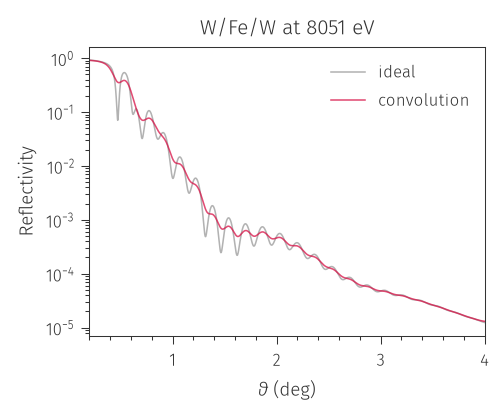

In [6]:
theta = res_ideal.quantity("theta", "deg")[0]

plt.figure()
plt.semilogy(theta, res_ideal.R[0, :], color="0.6", label="ideal")
plt.semilogy(theta, res_convolution.R[0, :], label="convolution")
plt.xlim(0.2, 4)
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("W/Fe/W at 8051 eV")
plt.show()

The resolution of 0.1° damps the Kiessig fringes of the period of about 0.17°, while the convolution takes a single calculation.

### Limits of the Convolution

The convolution can only use the points of the grid itself, which must resolve the profile and the features of the reflectivity.
This fails for coarse grids, e.g. the measured angles of a fit, which are often not denser than the features of the reflectivity.
Here, the convolution is calculated on a grid of 0.08°, which is about half the period of the fringes.

In [7]:
sim.theta = np.r_[0.2:4:0.08] * u.deg
res_coarse_convolution = sim.homogeneous_reflectivity_transmissivity()

Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.003824 s


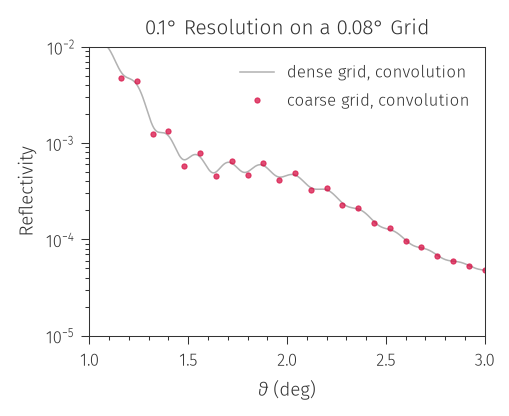

In [8]:
plt.figure()
plt.semilogy(theta, res_convolution.R[0, :], color="0.6", label="dense grid, convolution")
plt.semilogy(
    res_coarse_convolution.quantity("theta", "deg")[0],
    res_coarse_convolution.R[0, :],
    ".",
    label="coarse grid, convolution",
)
plt.xlim(1, 3)
plt.ylim(1e-5, 1e-2)
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("0.1° Resolution on a 0.08° Grid")
plt.show()

The convolution on the coarse grid samples the ideal fringes too sparsely and deviates from the result on the dense grid.
Similarly, the convolution of the energy needs the same angles for all photon energies, which fails for a scan of $q_z$.

### Quadrature

The `quadrature` avoids these limits by calculating the reflectivity on a grid of its own, i.e. the nodes $x_i$ in units of the FWHM, which are placed at the correct distance around every point of the experiment, independent of the grid of the experiment.
The integral is approximated by the reflectivity at these nodes and their weights $w_i$, which sum to one:

$$\langle R \rangle(\vartheta) \approx \sum_i w_i R(\vartheta + x_i \Delta\vartheta)$$

Such a weighted sum of function values at chosen nodes is called a *quadrature*, the common term for a numerical integration, e.g. the trapezoidal rule or the Gauss-Hermite quadrature.
Every node is a shifted copy of the experiment, at which the simulation is calculated once for all its points, i.e. the whole grid of the experiment is shifted by $x_i \Delta\vartheta$, so that any grid works.
Hence, the simulation is calculated for the number of spectral components times the energy nodes times the angle nodes, which is displayed as a message, see the {py:mod}`instrument <udkm1Dsim.simulations.scattering.instrument>` module for all formulas.

A quadrature of the resolution is also used by other reflectivity packages, e.g. the Gaussian quadrature of refnx {cite}`nelson2019` and the full convolution of GenX {cite}`bjorck2007`, which corresponds to the uniform nodes here.

:::{admonition} References {cite}`nelson2019,bjorck2007`
:class: seealso
- A. R. J. Nelson and S. W. Prescott, *refnx: neutron and X-ray reflectometry analysis in Python*, [J. Appl. Cryst. 52, 193 (2019)](https://doi.org/10.1107/S1600576718017296)
- M. Björck and G. Andersson, *GenX: an extensible X-ray reflectivity refinement program utilizing differential evolution*, [J. Appl. Cryst. 40, 1174 (2007)](https://doi.org/10.1107/S0021889807045086)
:::

### Nodes and Weights

The grid of the nodes is given by {py:func}`profile_nodes <udkm1Dsim.simulations.scattering.instrument.profile_nodes>` for the `points` and the `range` of an axis:

- `uniform`: equidistant nodes within $\pm$ `range` times the FWHM, weighted by the profile, which are robust for narrow features, e.g. Bragg peaks or resonances,
- `gaussian_quadrature`: Gauss-Hermite nodes of a Gaussian or Gauss-Legendre nodes of a box profile, which integrate smooth curves exactly with few nodes.

The uniform nodes of a box profile are the centers of equal parts of the box, while its Gaussian quadrature uses the Gauss-Legendre nodes, which have unequal weights.
These weights are not given by the profile, which is constant for a box, but by the condition that the sum over $n$ nodes integrates all polynomials up to the degree $2n - 1$ exactly, which moves the nodes towards the edges and reduces their weights there.
Hence, the Gaussian quadrature is very accurate for curves, which are smooth within the width of the profile, but not for several oscillations within it.

:::{hint}
For further reading on the quadrature, its nodes, weights, and errors, see [§3.5 Quadrature](https://dlmf.nist.gov/3.5) of the NIST Digital Library of Mathematical Functions, in particular [§3.5(v) Gauss Quadrature](https://dlmf.nist.gov/3.5#v).
:::

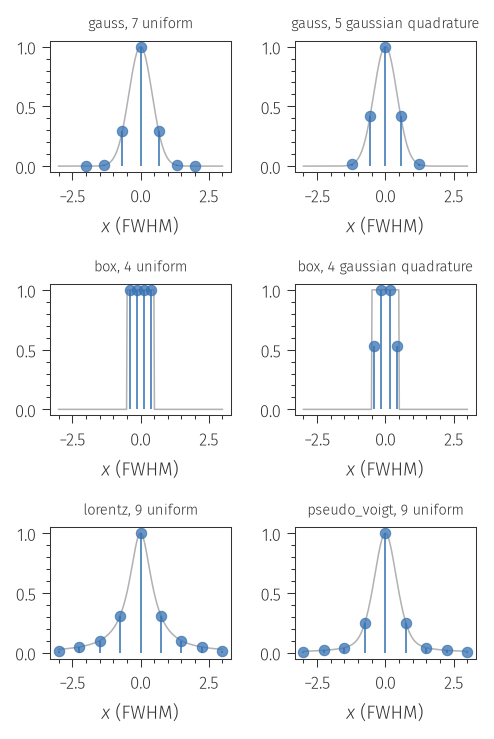

In [9]:
x = np.linspace(-3, 3, 601)
cases = [
    ("gauss", "uniform", 7, 2),
    ("gauss", "gaussian_quadrature", 5, 2),
    ("box", "uniform", 4, 2),
    ("box", "gaussian_quadrature", 4, 2),
    ("lorentz", "uniform", 9, 3),
    ("pseudo_voigt", "uniform", 9, 3),
]

plt.figure(figsize=[3.4, 5])
for k, (shape, nodes, points, node_range) in enumerate(cases):
    x_nodes, weights = instrument.profile_nodes(shape, nodes, points, node_range)
    profile = instrument.profile(shape, x)
    plt.subplot(3, 2, k + 1)
    plt.plot(x, profile / np.max(profile), color="0.6")
    plt.stem(x_nodes, weights / np.max(weights), basefmt=" ")
    plt.xlabel("$x$ (FWHM)")
    plt.title(f"{shape}, {points} {nodes.replace('_', ' ')}", fontsize=7)

plt.tight_layout()
plt.show()

The profiles and the weights are shown relative to their maximum.
An odd number of nodes contains the unshifted node $x = 0$.
The Lorentzian and pseudo-Voigt profiles have long tails, which are truncated by the `range` of their nodes, so that they need a larger `range` than a Gaussian.

### Number of Nodes

The quadrature is the default mode.
On the dense grid, it is calculated with an increasing number of uniform nodes and compared to the convolution.
The messages show the number of calculations of each setting.
For three nodes the theta resolution is just about 2 FWHM apart for a uniform spacing and results in a `UserWarning` as it is too coarse for the chosen profile.

In [10]:
sim.theta = np.r_[0.2:4:0.002] * u.deg
sim.instrument.theta_mode = "quadrature"
sim.instrument.theta_range = 2
R_quadrature = {}
for points in [3, 7, 15]:
    sim.instrument.theta_points = points
    R_quadrature[points] = sim.homogeneous_reflectivity_transmissivity().R[0, :]

Calculating _homogeneous_reflectivity_transmissivity_ ...
Instrument: 3 calculations (1 spectral component x 1 energy node x 3 angle nodes)
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.041504 s
Calculating _homogeneous_reflectivity_transmissivity_ ...
Instrument: 7 calculations (1 spectral component x 1 energy node x 7 angle nodes)
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.090935 s
Calculating _homogeneous_reflectivity_transmissivity_ ...
Instrument: 15 calculations (1 spectral component x 1 energy node x 15 angle nodes)


/home/schick/Programming/git/udkm1Dsim/udkm1Dsim/simulations/scattering/multilayer.py:1438: UserWarning: The 3 uniform nodes of the theta resolution are 2 FWHM apart within the theta_range of 2 FWHM, which is too coarse for the profile, so that the resolution is wrong, e.g. too small or too large! Use at least 7 theta_points for this range.
  return self._reduce_with_instrument(


Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.201634 s


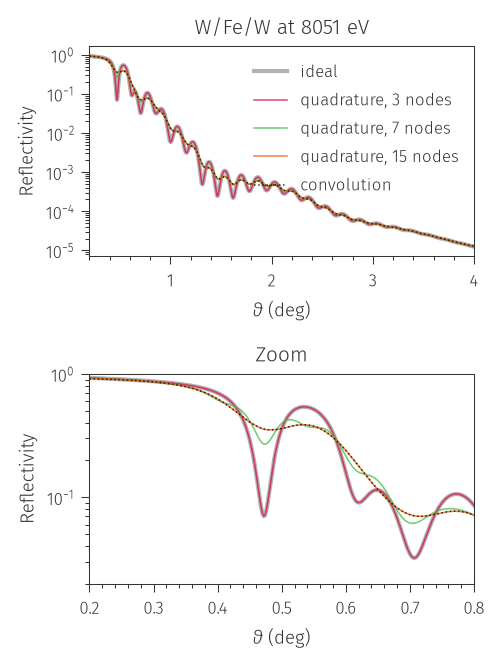

In [11]:
theta = res_ideal.quantity("theta", "deg")[0]

plt.figure(figsize=[3.4, 4.5])
for k, (xlim, title) in enumerate([((0.2, 4), "W/Fe/W at 8051 eV"), ((0.2, 0.8), "Zoom")]):
    plt.subplot(2, 1, k + 1)
    plt.semilogy(theta, res_ideal.R[0, :], color="0.6", lw=2, label="ideal")
    for points, R in R_quadrature.items():
        plt.semilogy(theta, R, label=f"quadrature, {points} nodes")
    plt.semilogy(theta, res_convolution.R[0, :], "k:", label="convolution")
    plt.xlim(xlim)
    plt.xlabel(r"$\vartheta$ (deg)")
    plt.ylabel("Reflectivity")
    plt.title(title)
plt.subplot(2, 1, 1)
plt.legend()
plt.subplot(2, 1, 2)
plt.ylim(0.02, 1)

plt.tight_layout()
plt.show()

Three uniform nodes within $\pm 2$ FWHM are 0.2° apart, so that they hardly damp the fringes, while 15 nodes agree with the convolution.
Hence, the number of nodes and their `range` should be increased until the result does not change anymore, especially for sharp features.

### Quadrature on a Coarse Grid

On the coarse grid of 0.08°, the quadrature with 15 nodes is compared to the convolution.

In [12]:
sim.theta = np.r_[0.2:4:0.08] * u.deg
sim.instrument.theta_points = 15
res_coarse_quadrature = sim.homogeneous_reflectivity_transmissivity()

Calculating _homogeneous_reflectivity_transmissivity_ ...
Instrument: 15 calculations (1 spectral component x 1 energy node x 15 angle nodes)
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.026449 s


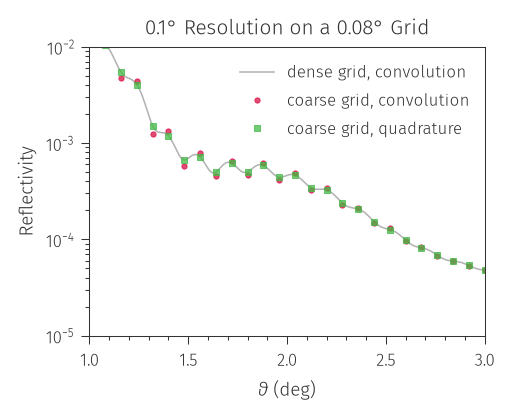

In [13]:
plt.figure()
plt.semilogy(theta, res_convolution.R[0, :], color="0.6", label="dense grid, convolution")
plt.semilogy(
    res_coarse_convolution.quantity("theta", "deg")[0],
    res_coarse_convolution.R[0, :],
    ".",
    label="coarse grid, convolution",
)
plt.semilogy(
    res_coarse_quadrature.quantity("theta", "deg")[0],
    res_coarse_quadrature.R[0, :],
    "s",
    ms=3,
    label="coarse grid, quadrature",
)
plt.xlim(1, 3)
plt.ylim(1e-5, 1e-2)
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("0.1° Resolution on a 0.08° Grid")
plt.show()

The quadrature on the coarse grid follows the result on the dense grid, while the convolution deviates from it.

### Choice of the Mode

The modes are summarized here, including the `qz` mode of the energy and the temporal resolution, which are shown below:

| axis | mode | calculations | grid of the experiment |
|---|---|---|---|
| angle, energy | `quadrature` | `points` per axis | any, e.g. measured angles |
| angle, energy | `convolution` | 1 | dense compared to the FWHM, for the energy the same angles for all photon energies |
| energy | `qz` | `points` | any, away from absorption edges |
| delays | temporal resolution | none | the delays of the maps |

The total number of calculations is the product of the spectral components and the nodes of the energy and the angle, e.g. 2 lines of an X-ray tube with 15 energy and 15 angle nodes already need 450 calculations.
Hence, the `convolution` is preferable on dense grids, the `gaussian_quadrature` for smooth curves, and the `uniform` nodes for sharp features, whose `points` and `range` should be increased until the result does not change anymore.

## Spectral Resolution

### Quadrature, Convolution, and the qz Mode

The spectral resolution is calculated by the same modes as the angular one.
In addition, the energy mode `qz` approximates the spectral spread at a fixed angle by the spread of the angle at the same scattering vector $q_z$:

$$\sin\vartheta' = \sin\vartheta (1 + \Delta E / E)$$

This avoids the calculation at shifted photon energies, but neglects the energy dependence of the dielectric tensor, which is valid away from absorption edges only.
Here, the reflectivity is calculated across the Fe $L_3$ edge at a grazing angle of 10° with a Gaussian spectral resolution of 2 eV (FWHM).

In [14]:
sim.disp_messages = False
sim.instrument = ud.InstrumentParameters()  # no instrument
sim.energy = np.r_[690:730:0.1] * u.eV
sim.theta = np.r_[10] * u.deg
res_edge_ideal = sim.homogeneous_reflectivity_transmissivity()

sim.instrument.energy_resolution = "gauss"
sim.instrument.energy_width = 2 * u.eV
sim.instrument.energy_points = 15
sim.instrument.energy_range = 3
res_edge = {}
for mode in ["quadrature", "convolution", "qz"]:
    sim.instrument.energy_mode = mode
    res_edge[mode] = sim.homogeneous_reflectivity_transmissivity()

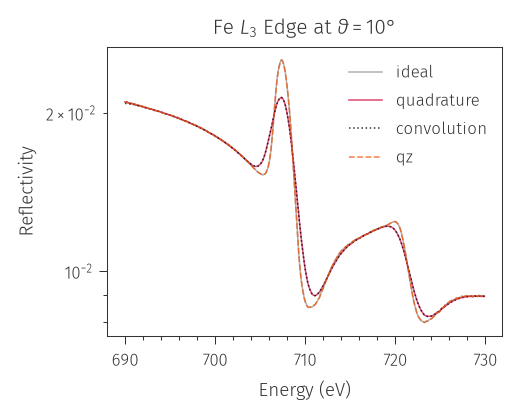

In [15]:
plt.figure()
plt.semilogy(res_edge_ideal.quantity("energy"), res_edge_ideal.R[:, 0], color="0.6", label="ideal")
for mode, style in [("quadrature", "-"), ("convolution", "k:"), ("qz", "--")]:
    plt.semilogy(res_edge[mode].quantity("energy"), res_edge[mode].R[:, 0], style, label=mode)
plt.xlabel("Energy (eV)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title(r"Fe $L_3$ Edge at $\vartheta = 10°$")
plt.show()

The quadrature and the convolution agree and broaden the resonance, while the `qz` mode stays close to the ideal reflectivity, as the spread of the angle at 10° hardly changes the reflectivity, which varies strongly with the photon energy across the edge.

Away from the absorption edges, the `qz` mode agrees with the quadrature, as shown for the angular scan at 8051 eV with a large bandwidth of 300 eV, e.g. of a multilayer monochromator.

In [16]:
sim.energy = np.r_[8051] * u.eV
sim.theta = np.r_[0.2:4:0.002] * u.deg
sim.instrument = ud.InstrumentParameters()  # no instrument
sim.instrument.energy_resolution = "gauss"
sim.instrument.energy_width = 300 * u.eV
sim.instrument.energy_points = 15
sim.instrument.energy_range = 3
res_bandwidth = {}
for mode in ["quadrature", "qz"]:
    sim.instrument.energy_mode = mode
    res_bandwidth[mode] = sim.homogeneous_reflectivity_transmissivity()

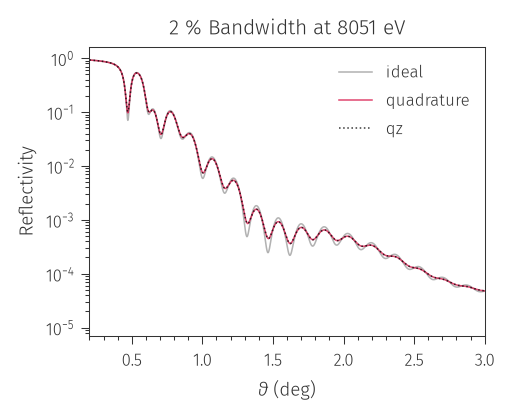

In [17]:
plt.figure()
plt.semilogy(theta, res_ideal.R[0, :], color="0.6", label="ideal")
plt.semilogy(theta, res_bandwidth["quadrature"].R[0, :], label="quadrature")
plt.semilogy(theta, res_bandwidth["qz"].R[0, :], "k:", label="qz")
plt.xlim(0.2, 3)
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("2 % Bandwidth at 8051 eV")
plt.show()

Both modes agree, and the bandwidth damps the Kiessig fringes, as for an angular resolution of the same $q_z$, which grows with $\tan\vartheta$.

## Spectrum of the Source

The `spectrum` of the source is a list of its components with the `factor` $f$ and the `offset` $\delta$ of their photon energy $E_m = f E + \delta$, their `weight`, and an optional `width`, see the [dynamical X-ray example](#example_dynamical_xray) for the $K_{\alpha 1}$ and $K_{\alpha 2}$ lines of an X-ray tube.
Here, the second order of a grating monochromator with 2 % of the intensity is added to an energy scan around 354 eV, so that the second order crosses the Fe $L_3$ edge at 707 eV.

In [18]:
sim.instrument = ud.InstrumentParameters()  # no instrument
sim.energy = np.r_[345:370:0.1] * u.eV
sim.theta = np.r_[10] * u.deg
res_first_order = sim.homogeneous_reflectivity_transmissivity()

sim.instrument.spectrum = [
    {"weight": 0.98},  # first order
    {"factor": 2, "weight": 0.02},  # second order at twice the energy
]
res_second_order = sim.homogeneous_reflectivity_transmissivity()
sim.instrument

Parameter,Symbol,Value,Unit
theta_width,Δθ,0,deg
theta_eta,ηθ,0.5,
theta_points,nθ,7,
theta_range,rθ,2,
energy_width,ΔE,0,eV
energy_eta,ηE,0.5,
energy_points,nE,7,
energy_range,rE,2,
delay_width,Δt,0,ps
delay_eta,ηt,0.5,


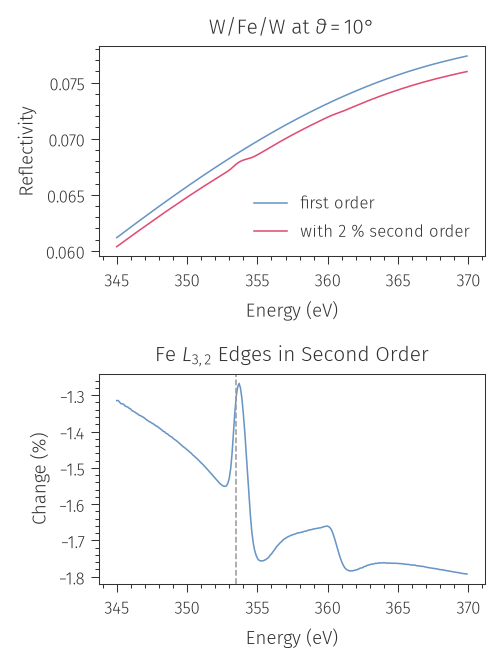

In [19]:
energy = res_first_order.quantity("energy")

plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
plt.plot(energy, res_first_order.R[:, 0], label="first order")
plt.plot(energy, res_second_order.R[:, 0], label="with 2 % second order")
plt.xlabel("Energy (eV)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title(r"W/Fe/W at $\vartheta = 10°$")

plt.subplot(2, 1, 2)
plt.plot(energy, 100 * (res_second_order.R[:, 0] / res_first_order.R[:, 0] - 1))
plt.axvline(707 / 2, color="0.6", ls="--")
plt.xlabel("Energy (eV)")
plt.ylabel("Change (%)")
plt.title(r"Fe $L_{3,2}$ Edges in Second Order")

plt.tight_layout()
plt.show()

The second order hardly changes the reflectivity itself, but its relative change shows the Fe $L_3$ and $L_2$ edges at half their photon energies, i.e. at about 353.5 eV and 360 eV, which could be mistaken for features of the sample.

## Footprint, Offsets, Intensity, and Background

At small angles, the beam is larger than the projection of the sample, so that only the fraction of the `footprint` hits the sample, which is calculated for a `box` or `gauss` beam of the `beam_width` (FWHM) on a sample of the `sample_length`.
The `theta_offset` and `energy_offset` shift the angles and photon energies of the experiment, while the intensities are scaled to $I_0 I + I_\mathrm{bkg}$ by the `I0` and the `background`, which are typical parameters of a fit, see the [data fitting example](#example_data_fitting).

In [20]:
sim.instrument = ud.InstrumentParameters()  # no instrument
sim.energy = np.r_[8051] * u.eV
sim.theta = np.r_[0.02:2:0.002] * u.deg
res_footprint_ideal = sim.homogeneous_reflectivity_transmissivity()

sim.instrument.beam_width = 0.1 * u.mm
sim.instrument.sample_length = 5 * u.mm
res_footprint = {}
for footprint in ["box", "gauss"]:
    sim.instrument.footprint = footprint
    res_footprint[footprint] = sim.homogeneous_reflectivity_transmissivity()

sim.instrument.theta_offset = 0.1 * u.deg
sim.instrument.I0 = 0.5
sim.instrument.background = 1e-3
res_footprint["gauss, offset, I0, background"] = sim.homogeneous_reflectivity_transmissivity()

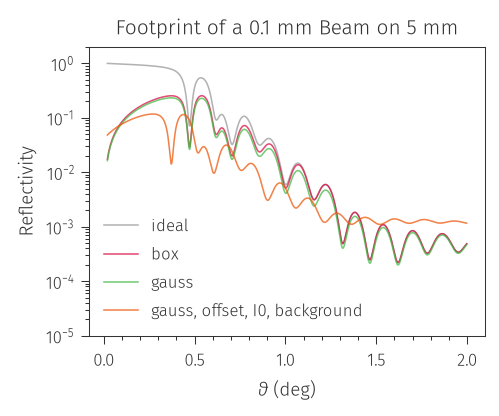

In [21]:
theta_footprint = res_footprint_ideal.quantity("theta", "deg")[0]

plt.figure()
plt.semilogy(theta_footprint, res_footprint_ideal.R[0, :], color="0.6", label="ideal")
for label, res in res_footprint.items():
    plt.semilogy(theta_footprint, res.R[0, :], label=label)
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.ylim([1e-5, 2])
plt.legend()
plt.title("Footprint of a 0.1 mm Beam on 5 mm")
plt.show()

The footprint reduces the reflectivity below about 1.1°, where the projection of the 5 mm long sample is smaller than the 0.1 mm wide beam.
The Gaussian beam reaches the full intensity more slowly, due to its tails.

## Magnetic Asymmetry

All parts of the instrument can be combined, which are then part of the metadata of the results.
Here, the resonant magnetic reflectivity of the trilayer at 707 eV is calculated for circularly polarized light with an angular and a spectral resolution, the footprint, and a background.

In [22]:
sim.instrument = ud.InstrumentParameters()  # no instrument
sim.energy = np.r_[707] * u.eV
sim.theta = np.r_[0.2:30:0.02] * u.deg
sim.set_polarization("circ +", "none")
res_ideal = sim.homogeneous_reflectivity_transmissivity()

sim.instrument.theta_resolution = "gauss"
sim.instrument.theta_width = 0.2 * u.deg
sim.instrument.energy_resolution = "pseudo_voigt"
sim.instrument.energy_width = 0.5 * u.eV
sim.instrument.energy_eta = 0.3
sim.instrument.energy_points = 11
sim.instrument.footprint = "gauss"
sim.instrument.beam_width = 0.1 * u.mm
sim.instrument.sample_length = 5 * u.mm
sim.instrument.background = 1e-5
sim.instrument

Parameter,Symbol,Value,Unit
theta_width,Δθ,0.2,deg
theta_eta,ηθ,0.5,
theta_points,nθ,7,
theta_range,rθ,2,
energy_width,ΔE,0.5,eV
energy_eta,ηE,0.3,
energy_points,nE,11,
energy_range,rE,2,
delay_width,Δt,0,ps
delay_eta,ηt,0.5,


Here, the simulation is repeated for 7 angular times 11 spectral nodes.

In [23]:
res_instrument = sim.homogeneous_reflectivity_transmissivity()
print(res_instrument.attrs["parameters"]["instrument"]["theta_width"])

0.2 deg


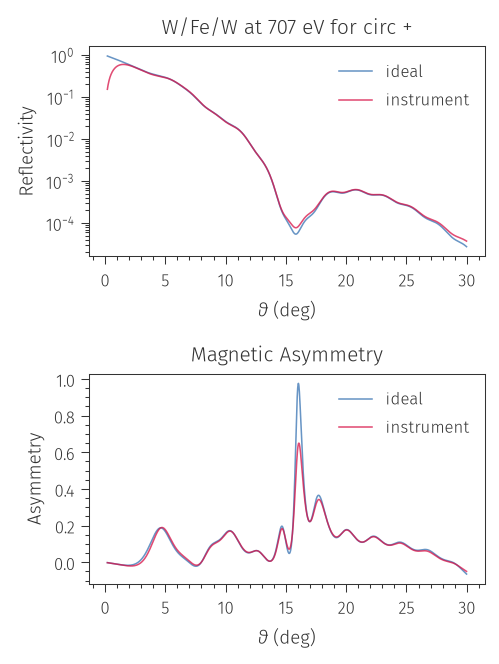

In [24]:
plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
plt.semilogy(res_ideal.quantity("theta", "deg")[0], res_ideal.R[0, :], label="ideal")
plt.semilogy(
    res_instrument.quantity("theta", "deg")[0], res_instrument.R[0, :], label="instrument"
)
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("W/Fe/W at 707 eV for circ +")

plt.subplot(2, 1, 2)
for res, label in [(res_ideal, "ideal"), (res_instrument, "instrument")]:
    plt.plot(
        res.quantity("theta", "deg")[0],
        ((res.R - res.R_phi) / (res.R + res.R_phi))[0, :],
        label=label,
    )
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Asymmetry")
plt.legend()
plt.title("Magnetic Asymmetry")

plt.tight_layout()
plt.show()

The footprint reduces the reflectivity at small angles, where the beam is larger than the projected sample, while the background lifts it at large angles.
The angular resolution of 0.2° and the spectral resolution of 0.5 eV smooth the minimum of the reflectivity at about 16° and reduce the peak of the magnetic asymmetry there.
The footprint and the intensity cancel in the asymmetry, while the background reduces it.

## Rotation and Ellipticity

The rotation and ellipticity of the polarization are not averaged themselves, but follow from the averaged polarization of the reflected light, i.e. its Stokes parameters.
For an energy scan at a fixed angle on a dense grid, the spectral resolution is convolved after a single calculation, which agrees with the quadrature, as shown for the Kerr rotation and ellipticity here.

In [25]:
sim.instrument = ud.InstrumentParameters()  # no instrument
sim.energy = np.r_[690:730:0.1] * u.eV
sim.theta = np.r_[10] * u.deg
sim.set_polarization("sigma", "none")
res_kerr_ideal = sim.homogeneous_rotation_ellipticity()

sim.instrument.energy_resolution = "gauss"
sim.instrument.energy_width = 1 * u.eV
sim.instrument.energy_range = 3
sim.instrument.energy_mode = "convolution"
res_kerr_convolution = sim.homogeneous_rotation_ellipticity()

sim.instrument.energy_mode = "quadrature"
sim.instrument.energy_points = 31
res_kerr_quadrature = sim.homogeneous_rotation_ellipticity()

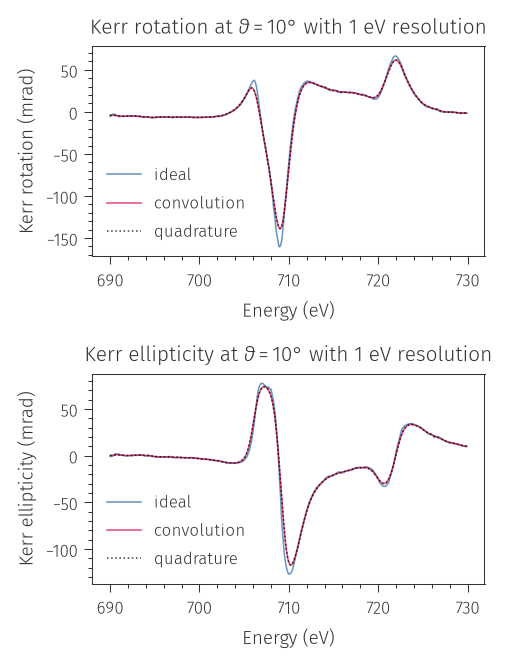

In [26]:
plt.figure(figsize=[3.4, 4.5])
for i, (name, label) in enumerate([("rot_R", "Kerr rotation"), ("ell_R", "Kerr ellipticity")]):
    plt.subplot(2, 1, i + 1)
    plt.plot(
        res_kerr_ideal.quantity("energy"),
        res_kerr_ideal.quantity(name, "mrad")[:, 0],
        label="ideal",
    )
    plt.plot(
        res_kerr_convolution.quantity("energy"),
        res_kerr_convolution.quantity(name, "mrad")[:, 0],
        label="convolution",
    )
    plt.plot(
        res_kerr_quadrature.quantity("energy"),
        res_kerr_quadrature.quantity(name, "mrad")[:, 0],
        "k:",
        label="quadrature",
    )
    plt.xlabel("Energy (eV)")
    plt.ylabel(f"{label} (mrad)")
    plt.legend()
    plt.title(f"{label} at $\\vartheta = 10°$ with 1 eV resolution")

plt.tight_layout()
plt.show()

Both modes agree, while the convolution takes a single calculation instead of 31.

## Temporal Resolution

The temporal resolution convolves the intensities of the inhomogeneous methods along their delays, which can be non-equidistant.
Before the first and after the last delay, the sample is held at its first and last state, e.g. the unexcited sample before the excitation, so that the delays should start well before the excitation.
The convolution needs the `delays` of the maps, which are taken from the upstream result of the [magnetization](#example_LLG) or [phonon simulations](#example_strain_pulses), or are given as for the hand-made `magnetization_map` here.
A temporal resolution without known delays raises an error, while given delays also label the result.

Here, a demagnetization of the Fe layer by 50 % within 1 ps is defined by hand, as in the [scattering overview](#example_scattering_overview).

In [27]:
delays = np.r_[-1:5:0.05] * u.ps
amplitude = 1 - 0.5 * (1 - np.exp(-delays.to("ps").magnitude / 1)) * (delays.magnitude > 0)

magnetization_map = np.zeros([len(delays), S.num_layers, 3])
magnetization_map[:, 1, 1] = amplitude  # the Fe layer along y

sim.instrument = ud.InstrumentParameters()  # no instrument
sim.energy = np.r_[707] * u.eV
sim.theta = np.r_[10] * u.deg
res_kerr_map = sim.inhomogeneous_rotation_ellipticity(magnetization_map=magnetization_map)

sim.instrument.delay_resolution = "gauss"
sim.instrument.delay_width = 0.5 * u.ps
res_kerr_delays = sim.inhomogeneous_rotation_ellipticity(
    magnetization_map=magnetization_map, delays=delays
)

Progress:   0%|          | 0/120 [00:00<?, ?it/s]

Progress:   0%|          | 0/120 [00:00<?, ?it/s]

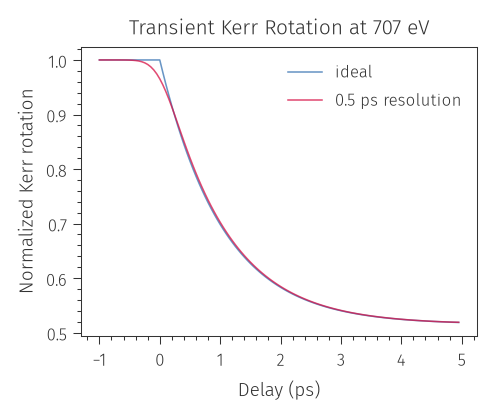

In [28]:
plt.figure()
plt.plot(delays, res_kerr_map.rot_R[:, 0, 0] / res_kerr_map.rot_R[0, 0, 0], label="ideal")
plt.plot(
    res_kerr_delays.quantity("delays", "ps"),
    res_kerr_delays.rot_R[:, 0, 0] / res_kerr_delays.rot_R[0, 0, 0],
    label="0.5 ps resolution",
)
plt.xlabel("Delay (ps)")
plt.ylabel("Normalized Kerr rotation")
plt.legend()
plt.title("Transient Kerr Rotation at 707 eV")
plt.show()

The temporal resolution of 0.5 ps smears the onset of the demagnetization, which then starts already before zero delay.